# PeptideLab — complete project walkthrough
Run all cells to inspect the trained project. Retraining is optional and kept separate so the demonstration is fast. Read the cell explanations before your viva.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'peptide_lab').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from peptide_lab.config import DATA, RESULTS
from peptide_lab.pipeline import ScreeningPipeline
print('Project:', ROOT)

Project: D:\College\SL\Project\Project_main


## 1. Inspect the data
GRAMPA trains the generator. Separate labeled benchmark datasets train activity and toxicity prediction. Exact splits and cleaning decisions are saved.

In [2]:
for task in ['activity', 'toxicity']:
    print(task.upper())
    audit = json.loads((RESULTS / f'{task}_data_audit.json').read_text())
    display(pd.DataFrame(audit['splits']).T)
    print('Train/test exact overlap removed:', audit['train_test_overlap_removed_from_train'])

,rows,positive,negative
train,10671,3082,7589
validation,2668,771,1897
test,8877,2563,6314


,rows,positive,negative
train,2627,1330,1297
validation,657,333,324
test,580,269,311


ACTIVITY
Train/test exact overlap removed: 0
TOXICITY
Train/test exact overlap removed: 0


## 2. Understand the neural networks
The LSTM VAE compresses sequences into a distribution and decodes samples. Two separate CNNs recognize activity and toxicity patterns. The forest is a baseline using simple descriptors.

In [3]:
from peptide_lab.networks import PeptideVAE, PeptideCNN
print(PeptideVAE())
print(PeptideCNN())

PeptideVAE(
  (embedding): Embedding(23, 32, padding_idx=0)
  (encoder): LSTM(32, 96, batch_first=True)
  (mu): Linear(in_features=96, out_features=24, bias=True)
  (logvar): Linear(in_features=96, out_features=24, bias=True)
  (init_h): Linear(in_features=24, out_features=96, bias=True)
  (init_c): Linear(in_features=24, out_features=96, bias=True)
  (decoder): LSTM(56, 96, batch_first=True)
  (output): Linear(in_features=96, out_features=23, bias=True)
)
PeptideCNN(
  (embedding): Embedding(21, 24, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(24, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): Conv1d(24, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (2): Conv1d(24, 32, kernel_size=(7,), stride=(1,), padding=(3,))
  )
  (head): Sequential(
    (0): Linear(in_features=121, out_features=48, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=48, out_features=1, bias=True)
  )
)


## 3. Read actual held-out results
The test set was not used for model selection. CNN/forest/ensemble selection uses validation ROC-AUC. High benchmark results do not establish biological function.

In [4]:
display(pd.read_csv(RESULTS / 'metrics_summary.csv'))

,Task,Model,accuracy,precision,recall,f1,mcc,roc_auc,average_precision
0,Activity,cnn,0.9554,0.9211,0.9247,0.9229,0.8915,0.9882,0.9784
1,Activity,random_forest,0.9589,0.9519,0.9032,0.9269,0.8989,0.9905,0.9822
2,Activity,ensemble (selected),0.9619,0.9459,0.9208,0.9332,0.9067,0.9916,0.9839
3,Toxicity,cnn (selected),0.9224,0.9375,0.8922,0.9143,0.8444,0.9718,0.9680
4,Toxicity,random_forest,0.9086,0.9000,0.9033,0.9017,0.8163,0.9617,0.9528
5,Toxicity,ensemble,0.9207,0.9240,0.9033,0.9135,0.8405,0.9719,0.9662


## 4. Inspect VAE learning
Cross-entropy is measured per non-padding token. Validation has no word dropout and uses the latent mean. The nonzero KL term does not by itself prove that every latent dimension is useful.

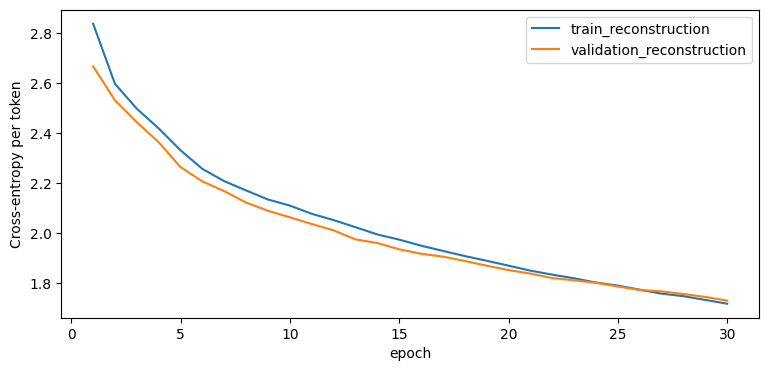

{
  "architecture": "LSTM VAE: embedding 32, hidden 96, latent 24; word dropout 0.2; KL warmup to 0.02",
  "splits": {
    "train": 5208,
    "validation": 651,
    "test": 651
  },
  "length_range": [
    5,
    60
  ],
  "test_teacher_forced_token_accuracy": 0.48951866189467536,
  "test_teacher_forced_cross_entropy": 1.6697235898725669,
  "generated": 500,
  "unique": 500,
  "uniqueness": 1.0,
  "novel_unique_vs_grampa": 1.0,
  "natural_end_rate": 1.0,
  "mean_entropy": 2.7083196191766974,
  "notes": "Sampling forbids special tokens and END before 5 residues, and caps length at 60. Alphabet/length validity is enforced by decoding, not evidence of biological validity. Novelty means exact non-match to GRAMPA only. Test reconstruction uses true previous tokens and is easier than free generation."
}


In [5]:
history = pd.read_csv(RESULTS / 'vae_history.csv')
history.plot(x='epoch', y=['train_reconstruction', 'validation_reconstruction'], figsize=(9,4))
plt.ylabel('Cross-entropy per token')
plt.show()
print(json.dumps(json.loads((RESULTS / 'vae_metrics.json').read_text()), indent=2))

## 5. Screen input sequences
These are demonstration inputs, not newly discovered peptides. Scores predict dataset labels, not MIC or comprehensive safety.

In [6]:
pipeline = ScreeningPipeline()
predictions = pipeline.predict(['GILSGILGAGKSLVCGLSGLC', 'KWKLFKKIGAVLKVL'])
display(predictions)

,rank,sequence,activity_score,activity_compact_score,activity_model_disagreement,toxicity_score,toxicity_compact_score,toxicity_model_disagreement,priority_score,weighted_difference_score,ranking_rule,activity_weight,prediction_engine,activity_screen_threshold,toxicity_screen_threshold,passes_property_screen,activity_prediction,toxicity_prediction,seen_in_grampa,seen_in_classifier_training,length,charge_proxy,hydrophobic_fraction,mean_hydropathy,entropy
0,1,GILSGILGAGKSLVCGLSGLC,0.999959,0.999959,0.000083,0.020718,0.020718,0.474511,97.924157,0.489620,product,0.5,compact,0.49,0.08,True,AMP-like,Non-toxic class,True,True,21,1,0.428571,1.442857,2.684017
1,2,KWKLFKKIGAVLKVL,0.999997,0.999997,0.000007,0.081220,0.081220,0.518814,91.877655,0.459388,product,0.5,compact,0.49,0.08,False,AMP-like,Non-toxic class,True,True,15,5,0.600000,0.540000,2.682589


## 6. Run the full generation and ranking workflow
Samples come from the VAE normal prior. Quality filters remove truncated, repetitive, known and duplicate sequences. Every passed-filter candidate is scored and ranked with explicit ranks.

In [7]:
candidates, audit = pipeline.generate(count=100, seed=42)
display(candidates[['rank','sequence','activity_score','toxicity_score','priority_score','length']])
print(json.dumps(audit, indent=2))

,rank,sequence,activity_score,toxicity_score,priority_score,length
0,1,RGRVRRYRRRNGVRVRLRMRRLPRRILNRL,0.999853,0.000260,99.959309,30
1,2,ALIGNLLKGAKETVMAIA,0.999191,0.000462,99.872859,18
2,3,GLLDFFGRGVLGVVNGRFKGIKRGVTHRHRRYPR,0.999730,0.002013,99.771742,34
3,4,GLGSSVSKVAGKGVPHLAQKALKLFEKF,0.999366,0.002603,99.676408,28
4,5,GIGKLLGHVAKTGLKAFAEALGNDK,0.999850,0.003533,99.631798,25
5,6,GLLRWLGRRVRS,0.999928,0.003666,99.626293,12
6,7,IYLRIFRGVFS,0.999845,0.003723,99.612294,11
7,8,PPSFKPVFVSSFL,0.999089,0.003002,99.609040,13
8,9,LPIRPGGYPGSPLIPAPPPRPRIRGLGSRVGTP,0.999541,0.003988,99.555473,33
9,10,GKLPTKVVGRLYTGL,0.999969,0.004899,99.506948,15


{
  "sampled": 100,
  "passed_filters": 81,
  "returned": 81,
  "rejected": {
    "length": 6,
    "truncated": 0,
    "low_complexity": 13,
    "known": 0,
    "duplicate": 0
  },
  "seed": 42,
  "temperature": 0.9,
  "length_range": [
    10,
    40
  ],
  "selection": "All passed-filter sequences scored and ranked together. No laboratory validation.",
  "prediction_engine": "compact",
  "ranking_rule": "product",
  "passed_property_screen": 58
}


## 7. Explain the ranking
`priority = 100 × activity_score × (1 − toxicity_score)`. This explicit preference score is not a calibrated probability of safety or success.

In [8]:
import numpy as np
assert np.allclose(candidates.priority_score, 100*candidates.activity_score*(1-candidates.toxicity_score))
print('Ranking formula verified.')
print('Exact GRAMPA matches:', int(candidates.seen_in_grampa.sum()))

Ranking formula verified.
Exact GRAMPA matches: 0


## 8. Reproduce training (optional)
Run `python -m peptide_lab.training` from the project root. Then run `python -m peptide_lab.pipeline` and `python scripts/build_report.py` to refresh the demonstration and report. Do not retrain during the live evaluation.

## 9. Limitations
No experimental validation; no MIC/species model; uncalibrated scores; exact-match rather than similarity-disjoint splits; length bias; exact novelty only. We use learned residue embeddings, not the baseline paper’s ESM-2 architecture.

## 10. Show the frontend
Run `python -m streamlit run app.py` and open http://127.0.0.1:8501.